In [6]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import Rectangle
 
sns.set_theme(style="whitegrid", context="notebook")
 
df = pd.read_csv("merged_mrc.csv")

In [8]:
df1 = pd.read_csv("mrc_table1.csv", usecols=["super_opeid", "trend_parq1", "trend_bottom40"])
df2 = pd.read_csv("mrc_table2.csv")

merged_mrc = df2.merge(df1, on="super_opeid", how="inner")

# Drop rows where super_opeid is less than 0
merged_mrc = merged_mrc[merged_mrc["super_opeid"] >= 0]

merged_mrc.to_csv("merged_mrc.csv", index=False)

In [8]:
df = pd.read_csv("merged_mrc.csv", usecols=["tier", "par_q1", "par_q5"]).dropna()
df["gap"] = df["par_q5"] - df["par_q1"]


In [9]:
df = pd.read_csv("merged_mrc.csv")

In [10]:
df.shape

(2199, 87)

In [11]:
df["type_label"] = df["type"].map({1: "Public", 2: "Private nonprofit", 3: "For-profit"})
type_order = ["Public", "Private nonprofit", "For-profit"]
type_palette = dict(zip(type_order, ["#1f77b4", "#ff7f0e", "#2ca02c"]))
 
tier_order = df.sort_values("tier")["tier_name"].unique().tolist()

df["imbalance"] = df["par_q5"] - df["par_q1"]                         # Q1.2
df["rank_gap"] = df["k_rank_cond_parq5"] - df["k_rank_cond_parq1"]    # Q3.2
rank_cols = [f"k_rank_cond_parq{i}" for i in range(1, 6)]

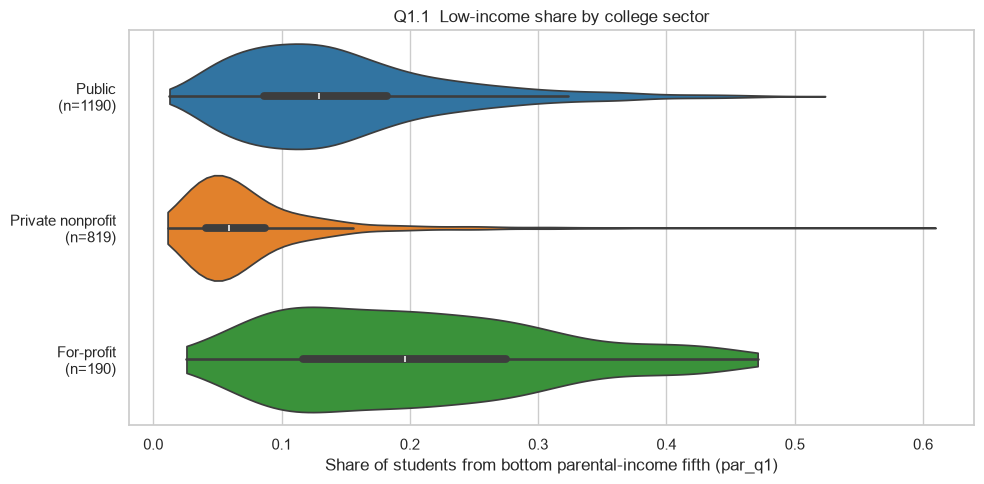

In [12]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.violinplot(data=df, y="type_label", x="par_q1", order=type_order, hue="type_label",
               palette=type_palette, inner="box", cut=0, legend=False, orient="h", ax=ax)
ax.set_yticks(range(3))
ax.set_yticklabels([f"{t}\n(n={(df['type_label'] == t).sum()})" for t in type_order])
ax.set_ylabel("")
ax.set_xlabel("Share of students from bottom parental-income fifth (par_q1)")
ax.set_title("Q1.1  Low-income share by college sector")

plt.tight_layout()
plt.show()

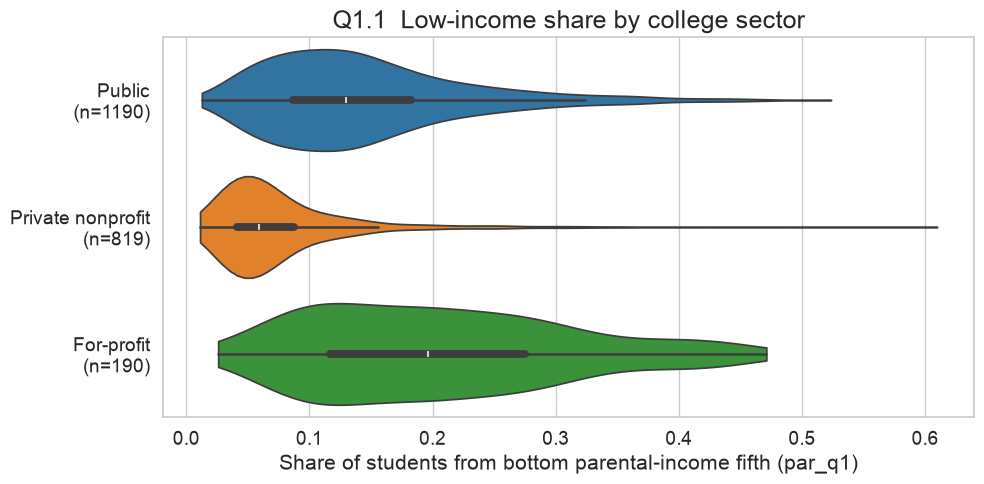

In [13]:
fig, ax = plt.subplots(figsize=(10, 5))

sns.violinplot(data=df, y="type_label", x="par_q1", order=type_order, hue="type_label",
               palette=type_palette, inner="box", cut=0, legend=False, orient="h", ax=ax)
ax.set_yticks(range(3))
ax.set_yticklabels([f"{t}\n(n={(df['type_label'] == t).sum()})" for t in type_order], fontsize=14)
ax.tick_params(axis="x", labelsize=14)
ax.set_ylabel("")
ax.set_xlabel("Share of students from bottom parental-income fifth (par_q1)", fontsize=15)
ax.set_title("Q1.1  Low-income share by college sector", fontsize=18)

plt.tight_layout()
plt.show()

In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

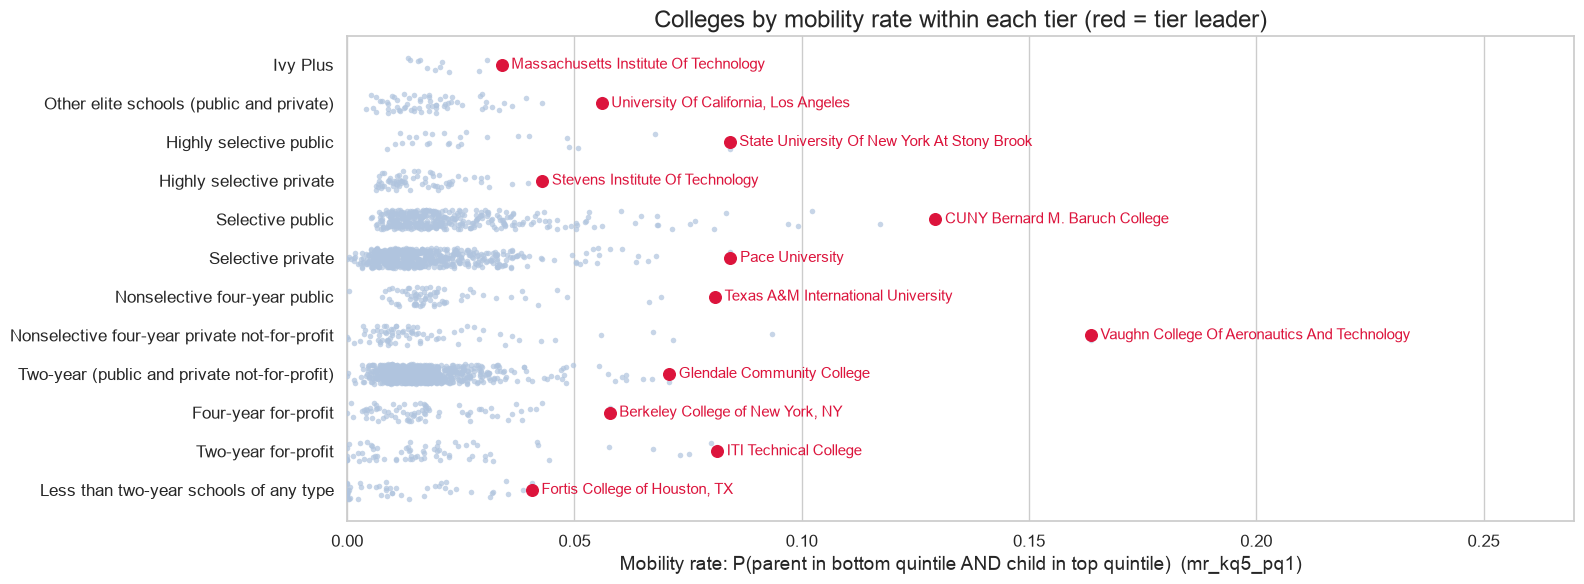

In [15]:
fig, ax = plt.subplots(figsize=(16, 6))
sns.stripplot(data=df, y="tier_name", x="mr_kq5_pq1", order=tier_order, color="lightsteelblue",
              size=4, alpha=0.7, jitter=0.25, ax=ax)

top = df.loc[df.groupby("tier_name")["mr_kq5_pq1"].idxmax()]
row_pos = pd.Categorical(top["tier_name"], categories=tier_order).codes

ax.scatter(top["mr_kq5_pq1"], row_pos, color="crimson", s=70, zorder=5)

bars = ax.barh(row_pos, top["mr_kq5_pq1"], height=0.1, alpha=0)
ax.bar_label(bars, labels=top["name"], padding=7, fontsize=11, color="crimson")

ax.set_xlim(0, df["mr_kq5_pq1"].max() * 1.65)
ax.tick_params(axis="both", labelsize=12)
ax.set_xlabel("Mobility rate: P(parent in bottom quintile AND child in top quintile)  (mr_kq5_pq1)", fontsize=14)
ax.set_ylabel("")
ax.set_title("Colleges by mobility rate within each tier (red = tier leader)", fontsize=17)

plt.tight_layout()
plt.show()

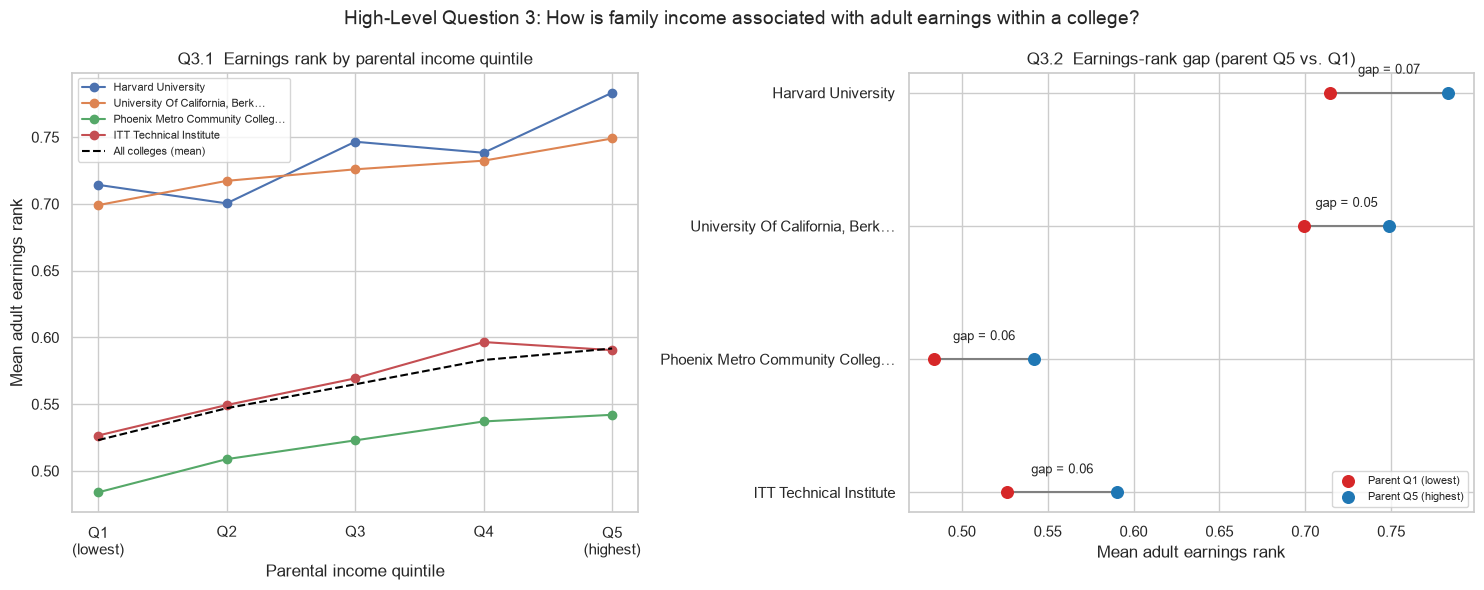

In [37]:
selected = ["Harvard University", "University Of California, Berkeley"]
selected.append(df[df["tier"] == 9].nlargest(1, "count")["name"].iloc[0])    # largest two-year
selected.append(df[df["tier"] == 10].nlargest(1, "count")["name"].iloc[0])   # largest four-year for-profit
sel = df[df["name"].isin(selected)].set_index("name").loc[selected]
short = {n: (n if len(n) < 32 else n[:30] + "…") for n in selected}
 
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
 
for n in selected:
    axes[0].plot(range(1, 6), sel.loc[n, rank_cols].astype(float), marker="o", label=short[n])
axes[0].plot(range(1, 6), df[rank_cols].mean(), color="black", linestyle="--", label="All colleges (mean)")
axes[0].set_xticks(range(1, 6))
axes[0].set_xticklabels(["Q1\n(lowest)", "Q2", "Q3", "Q4", "Q5\n(highest)"])
axes[0].set_xlabel("Parental income quintile")
axes[0].set_ylabel("Mean adult earnings rank")
axes[0].set_title("Q3.1  Earnings rank by parental income quintile")
axes[0].legend(fontsize=8)
 
ypos = np.arange(len(selected))
axes[1].hlines(ypos, sel["k_rank_cond_parq1"], sel["k_rank_cond_parq5"], color="gray")
axes[1].scatter(sel["k_rank_cond_parq1"], ypos, color="tab:red", s=70, label="Parent Q1 (lowest)", zorder=3)
axes[1].scatter(sel["k_rank_cond_parq5"], ypos, color="tab:blue", s=70, label="Parent Q5 (highest)", zorder=3)
for i, n in enumerate(selected):
    mid = (sel.loc[n, "k_rank_cond_parq1"] + sel.loc[n, "k_rank_cond_parq5"]) / 2
    axes[1].text(mid, i - 0.12, f"gap = {sel.loc[n, 'rank_gap']:.2f}", ha="center", va="bottom", fontsize=9)
axes[1].set_yticks(ypos)
axes[1].set_yticklabels([short[n] for n in selected])
axes[1].invert_yaxis()
axes[1].set_xlabel("Mean adult earnings rank")
axes[1].set_title("Q3.2  Earnings-rank gap (parent Q5 vs. Q1)")
axes[1].legend(fontsize=8, loc="lower right")
 
fig.suptitle("High-Level Question 3: How is family income associated with adult earnings within a college?", fontsize=14)
plt.tight_layout()
plt.show()

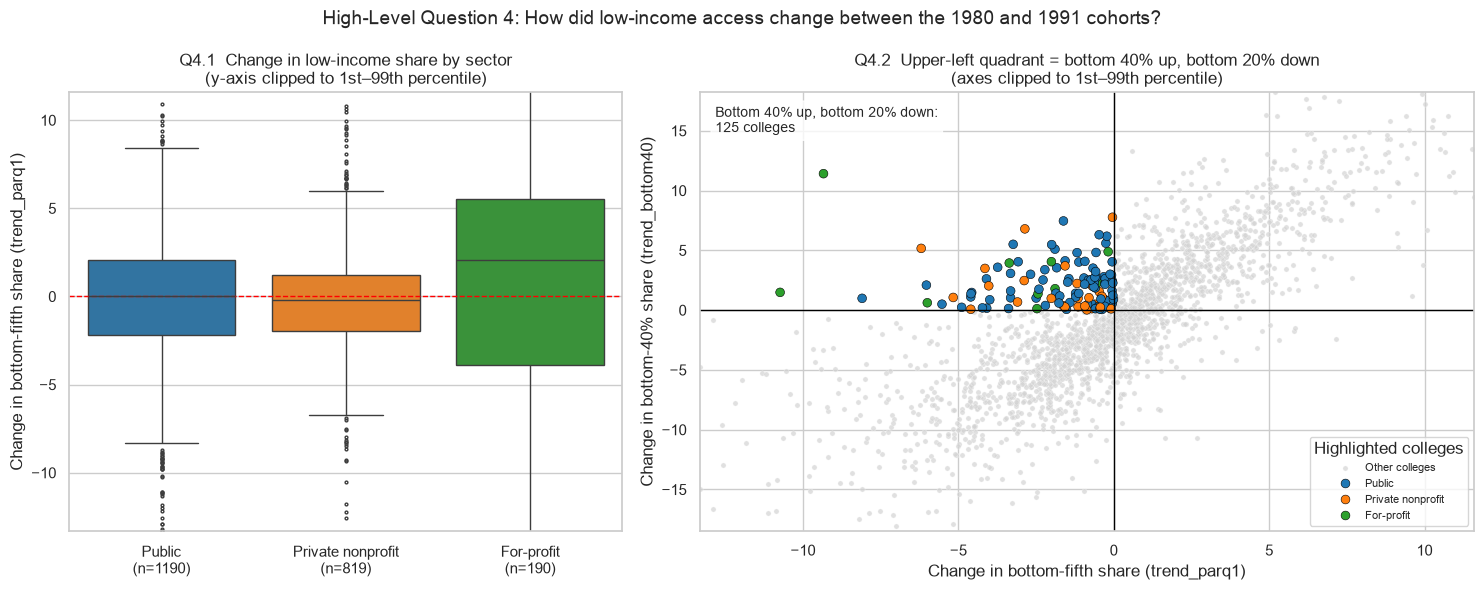

In [38]:
diverge = (df["trend_bottom40"] > 0) & (df["trend_parq1"] < 0)
 
fig, axes = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1, 1.4]})
 
sns.boxplot(data=df, x="type_label", y="trend_parq1", order=type_order, hue="type_label",
            palette=type_palette, fliersize=2, legend=False, ax=axes[0])
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)

lo, hi = df["trend_parq1"].quantile([0.01, 0.99])
axes[0].set_ylim(lo, hi)
axes[0].set_xticks(range(3))
axes[0].set_xticklabels([f"{t}\n(n={(df['type_label'] == t).sum()})" for t in type_order])
axes[0].set_xlabel("")
axes[0].set_ylabel("Change in bottom-fifth share (trend_parq1)")
axes[0].set_title("Q4.1  Change in low-income share by sector\n(y-axis clipped to 1st–99th percentile)")
 
sns.scatterplot(data=df[~diverge], x="trend_parq1", y="trend_bottom40", color="lightgray",
                s=14, alpha=0.7, label="Other colleges", ax=axes[1])
sns.scatterplot(data=df[diverge], x="trend_parq1", y="trend_bottom40", hue="type_label",
                hue_order=type_order, palette=type_palette, s=40, edgecolor="black",
                linewidth=0.4, ax=axes[1])
axes[1].axhline(0, color="black", linewidth=1)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlim(df["trend_parq1"].quantile([0.01, 0.99]))
axes[1].set_ylim(df["trend_bottom40"].quantile([0.01, 0.99]))
axes[1].text(0.02, 0.97, f"Bottom 40% up, bottom 20% down:\n{diverge.sum()} colleges",
             transform=axes[1].transAxes, va="top", fontsize=10,
             bbox=dict(boxstyle="round", facecolor="white", alpha=0.8))
axes[1].set_xlabel("Change in bottom-fifth share (trend_parq1)")
axes[1].set_ylabel("Change in bottom-40% share (trend_bottom40)")
axes[1].set_title("Q4.2  Upper-left quadrant = bottom 40% up, bottom 20% down\n(axes clipped to 1st–99th percentile)")
axes[1].legend(title="Highlighted colleges", fontsize=8, loc="lower right")
 
fig.suptitle("High-Level Question 4: How did low-income access change between the 1980 and 1991 cohorts?", fontsize=14)
plt.tight_layout()
plt.show()


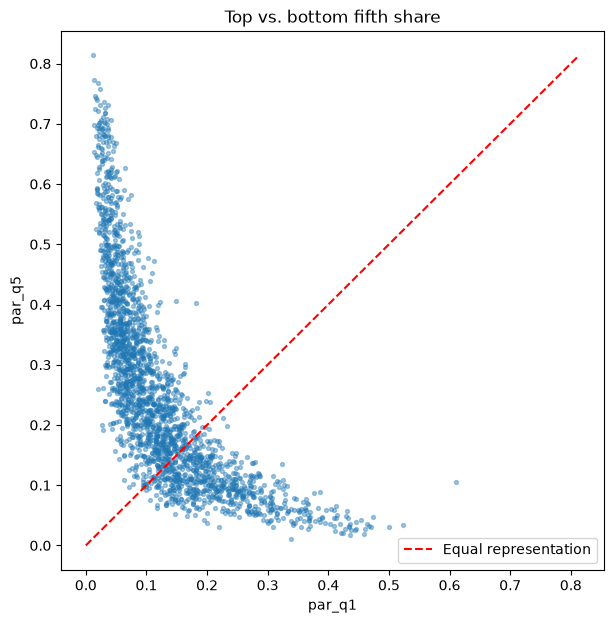

In [19]:
plt.figure(figsize=(7, 7))
plt.scatter(df["par_q1"], df["par_q5"], s=8, alpha=0.4)
m = max(df["par_q1"].max(), df["par_q5"].max())
plt.plot([0, m], [0, m], color="red", linestyle="--", label="Equal representation")
plt.xlabel("par_q1")
plt.ylabel("par_q5")
plt.legend()
plt.title("Top vs. bottom fifth share")
plt.show()

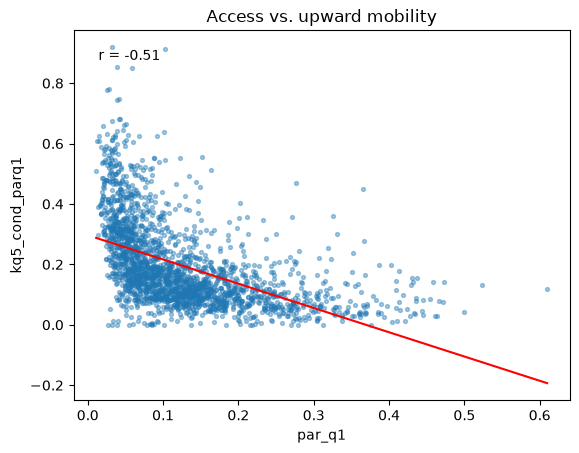

In [20]:
plt.figure()
x, y = df["par_q1"], df["kq5_cond_parq1"]
slope, intercept = np.polyfit(x, y, 1)
plt.scatter(x, y, s=8, alpha=0.4)
xs = np.linspace(x.min(), x.max(), 100)
plt.plot(xs, slope * xs + intercept, color="red")
plt.text(0.05, 0.92, f"r = {x.corr(y):.2f}", transform=plt.gca().transAxes)
plt.xlabel("par_q1")
plt.ylabel("kq5_cond_parq1")
plt.title("Access vs. upward mobility")
plt.show()

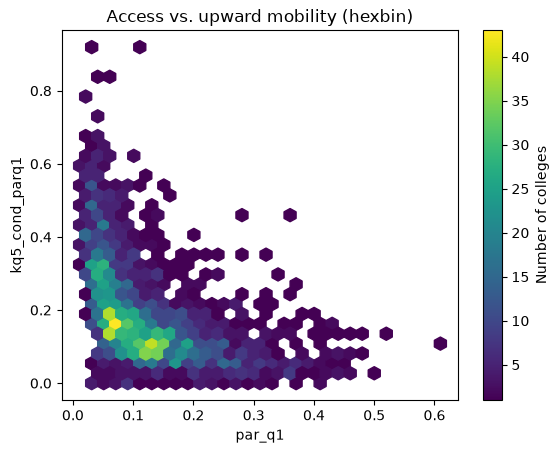

In [21]:
plt.figure()
hb = plt.hexbin(df["par_q1"], df["kq5_cond_parq1"], gridsize=30, cmap="viridis", mincnt=1)
plt.colorbar(hb, label="Number of colleges")
plt.xlabel("par_q1")
plt.ylabel("kq5_cond_parq1")
plt.title("Access vs. upward mobility (hexbin)")
plt.show()

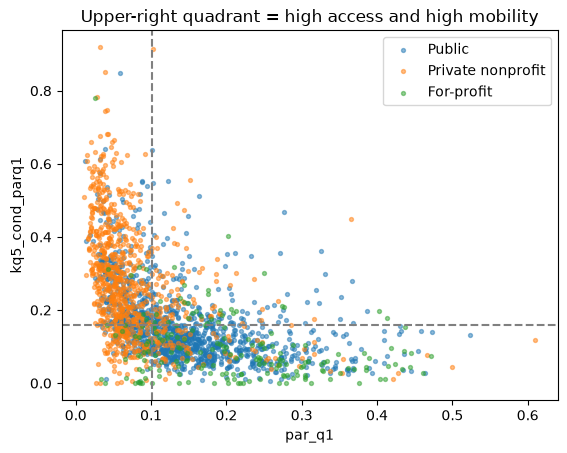

In [22]:
plt.figure()
for t, c in zip(type_order, type_colors):
    sub = df[df["type_label"] == t]
    plt.scatter(sub["par_q1"], sub["kq5_cond_parq1"], s=8, alpha=0.5, label=t, color=c)
plt.axvline(df["par_q1"].median(), color="gray", linestyle="--")
plt.axhline(df["kq5_cond_parq1"].median(), color="gray", linestyle="--")
plt.xlabel("par_q1")
plt.ylabel("kq5_cond_parq1")
plt.legend()
plt.title("Upper-right quadrant = high access and high mobility")
plt.show()

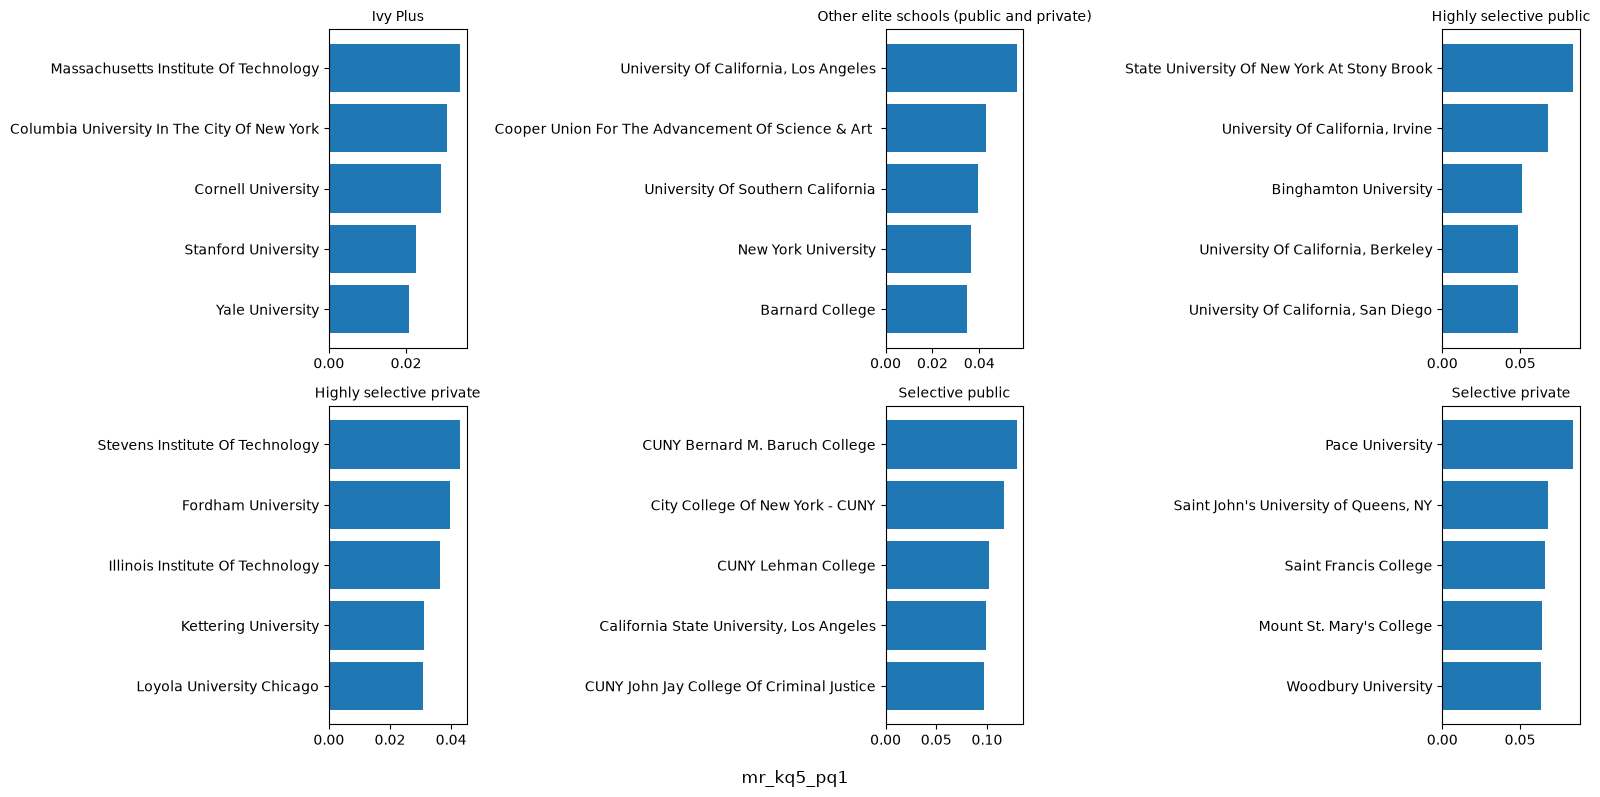

In [23]:
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, t in zip(axes.flat, tier_order[:6]):
    top = df[df["tier_name"] == t].nlargest(5, "mr_kq5_pq1").sort_values("mr_kq5_pq1")
    ax.barh(top["name"], top["mr_kq5_pq1"])
    ax.set_title(t, fontsize=10)
fig.supxlabel("mr_kq5_pq1")
plt.tight_layout()
plt.show()

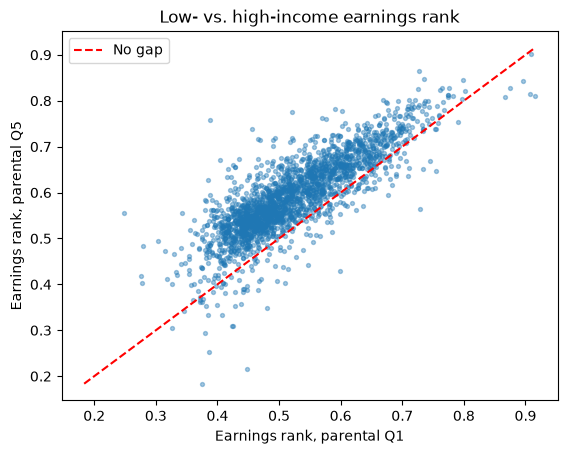

In [25]:
plt.figure()
plt.scatter(df["k_rank_cond_parq1"], df["k_rank_cond_parq5"], s=8, alpha=0.4)
lo = min(df["k_rank_cond_parq1"].min(), df["k_rank_cond_parq5"].min())
hi = max(df["k_rank_cond_parq1"].max(), df["k_rank_cond_parq5"].max())
plt.plot([lo, hi], [lo, hi], color="red", linestyle="--", label="No gap")
plt.xlabel("Earnings rank, parental Q1")
plt.ylabel("Earnings rank, parental Q5")
plt.legend()
plt.title("Low- vs. high-income earnings rank")
plt.show()

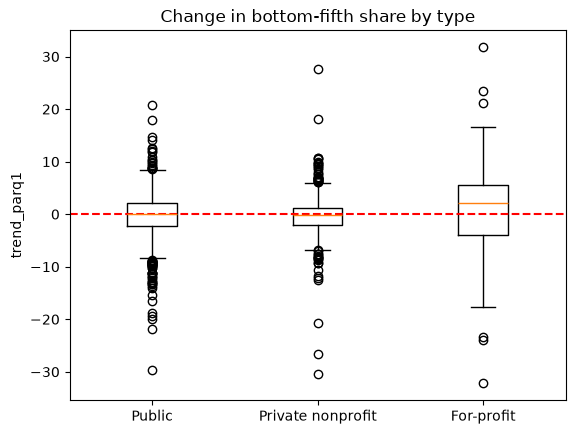

In [26]:
plt.figure()
data = [df.loc[df["type_label"] == t, "trend_parq1"] for t in type_order]
plt.boxplot(data)
plt.xticks([1, 2, 3], type_order)
plt.axhline(0, color="red", linestyle="--")
plt.ylabel("trend_parq1")
plt.title("Change in bottom-fifth share by type")
plt.show()

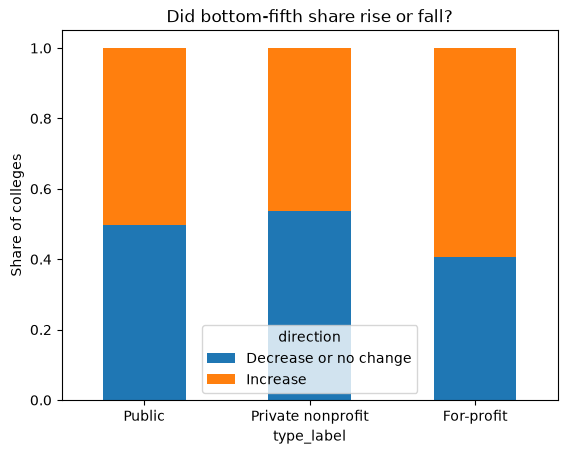

In [27]:
df["direction"] = np.where(df["trend_parq1"] > 0, "Increase", "Decrease or no change")
shares = pd.crosstab(df["type_label"], df["direction"], normalize="index").loc[type_order]
shares.plot(kind="bar", stacked=True)
plt.ylabel("Share of colleges")
plt.xticks(rotation=0)
plt.title("Did bottom-fifth share rise or fall?")
plt.show()

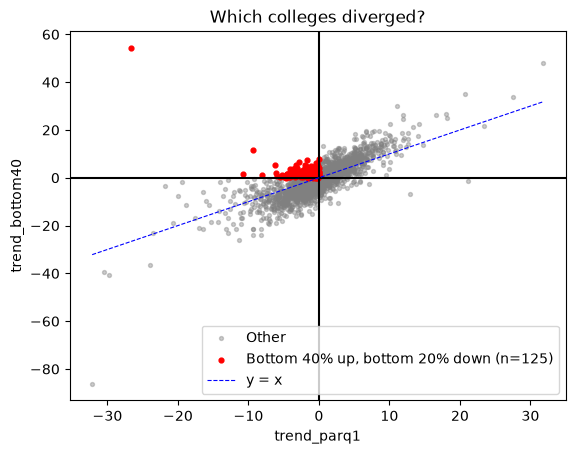

In [28]:
plt.figure()
plt.scatter(df.loc[~mask_diverge, "trend_parq1"], df.loc[~mask_diverge, "trend_bottom40"],
            s=8, alpha=0.4, color="gray", label="Other")
plt.scatter(df.loc[mask_diverge, "trend_parq1"], df.loc[mask_diverge, "trend_bottom40"],
            s=12, color="red", label=f"Bottom 40% up, bottom 20% down (n={mask_diverge.sum()})")
plt.axhline(0, color="black")
plt.axvline(0, color="black")
lim = [df["trend_parq1"].min(), df["trend_parq1"].max()]
plt.plot(lim, lim, linestyle="--", color="blue", linewidth=0.8, label="y = x")
plt.xlabel("trend_parq1")
plt.ylabel("trend_bottom40")
plt.legend()
plt.title("Which colleges diverged?")
plt.show()

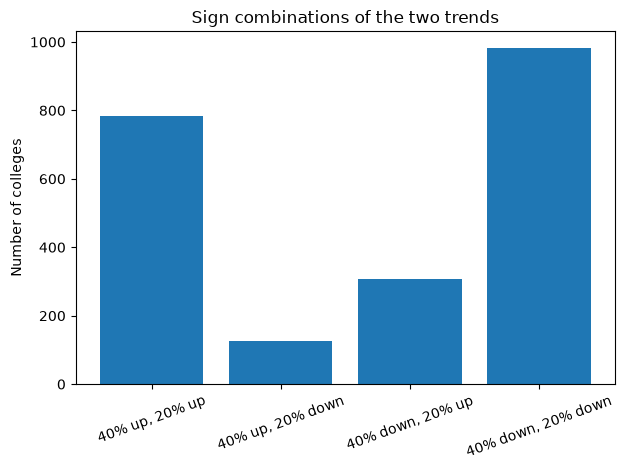

In [29]:
up40 = df["trend_bottom40"] > 0
up20 = df["trend_parq1"] > 0
counts = {
    "40% up, 20% up": (up40 & up20).sum(),
    "40% up, 20% down": (up40 & ~up20).sum(),
    "40% down, 20% up": (~up40 & up20).sum(),
    "40% down, 20% down": (~up40 & ~up20).sum(),
}
plt.figure()
plt.bar(counts.keys(), counts.values())
plt.xticks(rotation=20)
plt.ylabel("Number of colleges")
plt.title("Sign combinations of the two trends")
plt.tight_layout()
plt.show()